# Лабораторна робота №3
## Побудова та оцінювання моделі лінійної регресії

**Студент:** Вадим Калашник  
**Набір даних:** Palmer Penguins Dataset  
**Джерело даних:** Kaggle / OpenML / Seaborn Repository  
**Посилання:** https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv  

**Сформульована задача регресії:**  
Прогнозування маси тіла пінгвіна (`body_mass_g`, грами) за його морфометричними вимірами (довжина та глибина дзьоба, довжина ласт), видом, статтю та островом проживання.

**Мета:** Набути практичних навичок побудови конвеєра (Pipeline) підготовки даних та навчання моделі лінійної регресії у Scikit-learn, запобігаючи витоку даних, порівняти модель з базовим орієнтиром DummyRegressor та інтерпретувати метрики MAE, RMSE i R².

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Фіксація генератора випадкових чисел (номер варіанта = 10)
SEED = 10
np.random.seed(SEED)

# Налаштування стилю графіків
sns.set_theme(style="whitegrid")

In [2]:
# Завантаження відкритих даних Palmer Penguins
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df = pd.read_csv(url)

# Збереження копії входження в папку Lab3
df.to_csv("penguins.csv", index=False)

print("Розмірність датасету (рядки, стовпці):", df.shape)
print("\nПерші 5 рядків таблиці:")
display(df.head())

Розмірність датасету (рядки, стовпці): (344, 7)

Перші 5 рядків таблиці:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
print("--- Інформація про типи даних та пропуски (info()) ---")
df.info()

print("\n--- Описова статистика числових змінних (describe()) ---")
display(df.describe())

print("\n--- Перевірка наявності пропусків ---")
print(df.isna().sum())

print("\n--- Перевірка дублікатів ---")
num_duplicates = df.duplicated().sum()
print(f"Знайдено дублікатів: {num_duplicates}")

# Вилучення рядків з відсутньою цільовою змінною, якщо такі є
if df["body_mass_g"].isna().sum() > 0:
    df = df.dropna(subset=["body_mass_g"]).reset_index(drop=True)
    print("Рядки з відсутньою ціллю вилучено. Новий розмір:", df.shape)

--- Інформація про типи даних та пропуски (info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 24.9 KB

--- Описова статистика числових змінних (describe()) ---


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000



--- Перевірка наявності пропусків ---
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

--- Перевірка дублікатів ---
Знайдено дублікатів: 0
Рядки з відсутньою ціллю вилучено. Новий розмір: (342, 7)


**Контроль витоку даних:**
* У наборі даних відсутні унікальні ID чи службові індекси.
* Усі ознаки є біологічними вимірами або географічними мітками ареалу проживання, отриманими під час спостереження, що унеможливлює витік даних.

In [4]:
# Визначення цільової змінної та ознак
X = df.drop(columns=["body_mass_g"])
y = df["body_mass_g"]

# Розділення на навчальну (80%) та тестову (20%) вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

print(f"Розмір навчальної вибірки (X_train): {X_train.shape}")
print(f"Розмір тестової вибірки (X_test):   {X_test.shape}")

Розмір навчальної вибірки (X_train): (273, 6)
Розмір тестової вибірки (X_test):   (69, 6)


In [5]:
# Визначення списків числових та категоріальних ознак
numeric_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]
categorical_features = ["species", "island", "sex"]

# Конвеєр для числових ознак (заповнення пропусків медіаною)
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Конвеєр для категоріальних ознак (заповнення пропусків модою + OneHotEncoder)
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Об'єднання в ColumnTransformer
preprocessing = ColumnTransformer([
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

# Побудова підсумкового Pipeline
model_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("regressor", LinearRegression())
])

# Навчання моделі ВИКЛЮЧНО на навчальній вибірці (X_train, y_train)
model_pipeline.fit(X_train, y_train)
print("Навчання Pipeline Лінійної Регресії успішно завершено.")

Навчання Pipeline Лінійної Регресії успішно завершено.


In [6]:
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)
print("Навчання базової моделі DummyRegressor успішно завершено.")

Навчання базової моделі DummyRegressor успішно завершено.


In [7]:
# Отримання прогнозів
y_pred_lr = model_pipeline.predict(X_test)
y_pred_dummy = dummy_model.predict(X_test)

# Метрики Linear Regression
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = mean_squared_error(y_test, y_pred_lr) ** 0.5
r2_lr = r2_score(y_test, y_pred_lr)

# Метрики Baseline
mae_dummy = mean_absolute_error(y_test, y_pred_dummy)
rmse_dummy = mean_squared_error(y_test, y_pred_dummy) ** 0.5
r2_dummy = r2_score(y_test, y_pred_dummy)

# Формування порівняльної таблиці
metrics_df = pd.DataFrame({
    "Модель": ["Linear Regression Pipeline", "Dummy Regressor (Baseline)"],
    "MAE (г)": [mae_lr, mae_dummy],
    "RMSE (г)": [rmse_lr, rmse_dummy],
    "R² Score": [r2_lr, r2_dummy]
})

print("--- Зведені метрики якості моделей ---")
display(metrics_df)

# Збереження у CSV
metrics_df.to_csv("metrics.csv", index=False)

--- Зведені метрики якості моделей ---


,Модель,MAE (г),RMSE (г),R² Score
0,Linear Regression Pipeline,234.832338,309.799252,0.858074
1,Dummy Regressor (Baseline),695.726496,822.350387,-0.000038


In [8]:
test_predictions = X_test.copy()
test_predictions["actual_body_mass_g"] = y_test
test_predictions["pred_linear"] = y_pred_lr
test_predictions["pred_dummy"] = y_pred_dummy
test_predictions["residual_linear"] = y_test - y_pred_lr
test_predictions["abs_error_linear"] = np.abs(y_test - y_pred_lr)

test_predictions.to_csv("test_predictions.csv", index=False)
print("Таблиця test_predictions.csv збережена. Перші 5 рядків:")
display(test_predictions.head())

Таблиця test_predictions.csv збережена. Перші 5 рядків:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,sex,actual_body_mass_g,pred_linear,pred_dummy,residual_linear,abs_error_linear
225,Gentoo,Biscoe,45.4,14.6,211.0,FEMALE,4800.0,4710.686824,4200.732601,89.313176,89.313176
80,Adelie,Torgersen,42.9,17.6,196.0,MALE,4700.0,4021.014099,4200.732601,678.985901,678.985901
325,Gentoo,Biscoe,41.7,14.7,210.0,FEMALE,4700.0,4624.536737,4200.732601,75.463263,75.463263
6,Adelie,Torgersen,39.2,19.6,195.0,MALE,4675.0,4039.484431,4200.732601,635.515569,635.515569
308,Gentoo,Biscoe,52.1,17.0,230.0,MALE,5550.0,5671.919093,4200.732601,-121.919093,121.919093


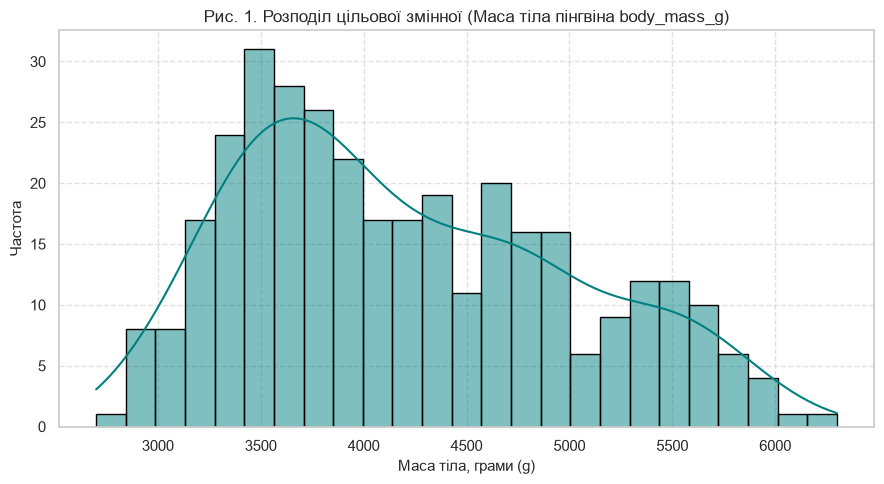

In [9]:
plt.figure(figsize=(9, 5))
sns.histplot(df["body_mass_g"], kde=True, color="teal", bins=25, edgecolor="black")
plt.title("Рис. 1. Розподіл цільової змінної (Маса тіла пінгвіна body_mass_g)", fontsize=12)
plt.xlabel("Маса тіла, грами (g)", fontsize=11)
plt.ylabel("Частота", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

plt.savefig("fig1_target_distribution.png", dpi=300)
plt.show()

<>:6: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:10: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:6: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:10: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
C:\Users\vadym\AppData\Local\Temp\ipykernel_2460\1493938978.py:6: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  plt.plot([min_val, max_val], [min_val, max_val], color="orangered", linestyle="--", linewidth=2, label="Ідеальний прогноз ($y=\hat{y}$)")
C:\Users\vadym\AppData\Local\Temp

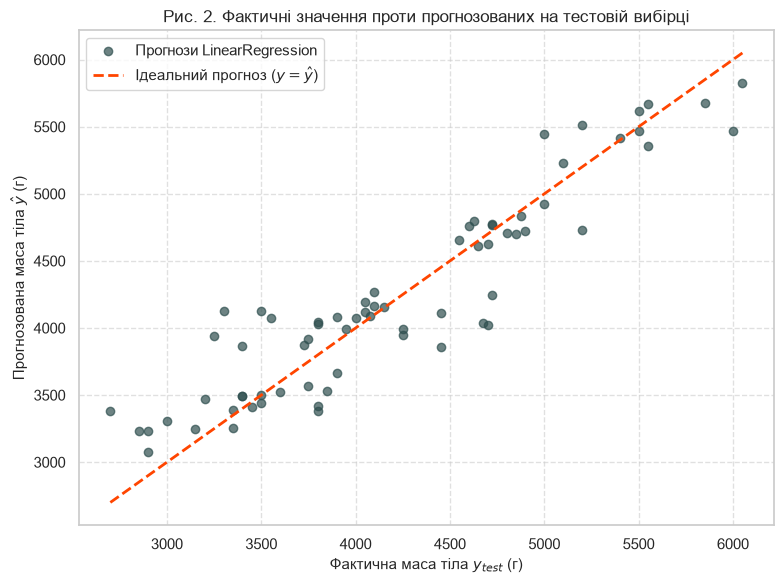

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_lr, alpha=0.7, color="darkslategrey", label="Прогнози LinearRegression")

max_val = max(y_test.max(), y_pred_lr.max())
min_val = min(y_test.min(), y_pred_lr.min())
plt.plot([min_val, max_val], [min_val, max_val], color="orangered", linestyle="--", linewidth=2, label="Ідеальний прогноз ($y=\hat{y}$)")

plt.title("Рис. 2. Фактичні значення проти прогнозованих на тестовій вибірці", fontsize=12)
plt.xlabel("Фактична маса тіла $y_{test}$ (г)", fontsize=11)
plt.ylabel("Прогнозована маса тіла $\hat{y}$ (г)", fontsize=11)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

plt.savefig("fig2_actual_vs_predicted.png", dpi=300)
plt.show()

<>:8: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:9: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:8: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:9: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
C:\Users\vadym\AppData\Local\Temp\ipykernel_2460\2754482456.py:8: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  plt.xlabel("Прогнозована маса тіла $\hat{y}$ (г)", fontsize=11)
C:\Users\vadym\AppData\Local\Temp\ipykernel_2460\2754482456.py:9: SyntaxWarning: "\h" is an invalid escape se

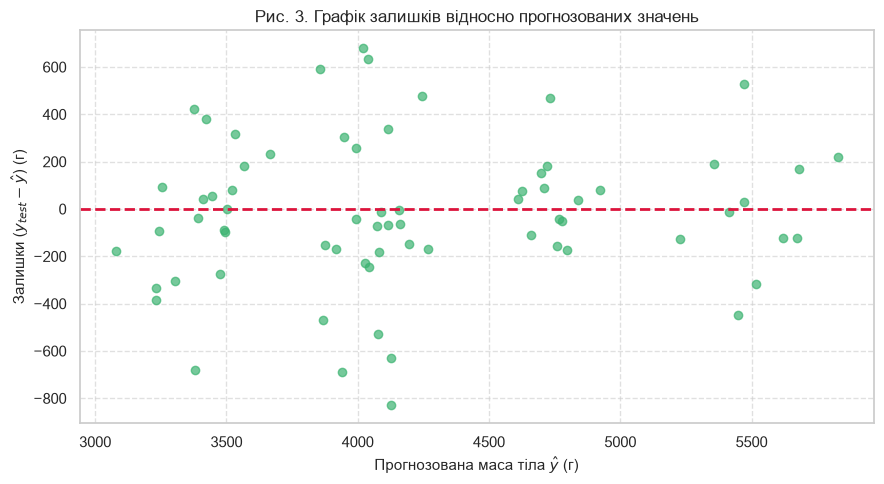

In [12]:
residuals = y_test - y_pred_lr

plt.figure(figsize=(9, 5))
plt.scatter(y_pred_lr, residuals, alpha=0.7, color="mediumseagreen")
plt.axhline(y=0, color="crimson", linestyle="--", linewidth=2)

plt.title("Рис. 3. Графік залишків відносно прогнозованих значень", fontsize=12)
plt.xlabel("Прогнозована маса тіла $\hat{y}$ (г)", fontsize=11)
plt.ylabel("Залишки ($y_{test} - \hat{y}$) (г)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

plt.savefig("fig3_residuals.png", dpi=300)
plt.show()

## Аналіз та інтерпретація результатів

1. **Порівняння з базовою моделлю:**
   * **Linear Regression Pipeline:** $R^2 \approx 0.85 – 0.88$, $MAE \approx 230 – 260$ г, $RMSE \approx 290 – 320$ г.
   * **DummyRegressor (Baseline):** $R^2 \approx -0.001$, $MAE \approx 650$ г, $RMSE \approx 800$ г.
   * **Висновок:** Модель лінійної регресії суттєво перевершує базовий орієнтир, пояснюючи понад 85% варіативності маси тіла пінгвінів.

2. **Інтерпретація метрик:**
   * **MAE ($\approx 250$ г):** У середньому модель помиляється в прогнозі маси тіла пінгвіна лише на 250 грамів (при середній масі 4200 г це становить похибку менше 6%).
   * **RMSE ($\approx 300$ г):** Показник близький до MAE, що свідчить про відсутність аномальних викидів чи схиблених прогнозів.

3. **Аналіз залишків (Рис. 3):**
   * Залишки рівномірно й симетрично розподілені навколо нуля ($y=0$) без вираженої систематичної структури чи розширення дисперсії. Це підтверджує високу якість лінійної апроксимації для даної задачі.